In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
df=pd.read_csv("emergency_service.csv")
df

,Timestamp,Incident_Severity,Incident_Type,Region_Type,Traffic_Congestion,Weather_Condition,Ambulance_Availability,Hospital_Capacity,Distance_to_Incident,Number_of_Injuries,Specialist_Availability,Road_Type,Emergency_Level,Ambulance_Speed,Fuel_Level,Weather_Impact,Dispatch_Coordinator,Response_Time
0,01/01/2018 00:00,Low,Cardiac Arrest,Suburban,High,Clear,Available,91,8.89,1,Unavailable,Highway,Major,43.549849,90.030756,Severe,AI,20.870220
1,01/01/2018 00:10,Low,Other,Urban,Moderate,Clear,Available,28,28.10,2,Unavailable,Highway,Critical,30.687975,88.255008,Moderate,Human,24.486195
2,01/01/2018 00:20,Medium,Cardiac Arrest,Suburban,High,Rainy,Available,83,40.43,1,Unavailable,Unpaved Road,Minor,44.456331,97.719622,No Impact,Human,18.760740
3,01/01/2018 00:30,Low,Accident,Urban,Moderate,Clear,Available,31,18.97,3,Available,Highway,Minor,35.879968,60.234672,No Impact,Human,18.169534
4,01/01/2018 00:40,Low,Cardiac Arrest,Urban,Moderate,Stormy,Available,52,16.31,3,Available,Highway,Minor,26.369383,71.083564,Moderate,Human,5.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368060,30/12/2024 23:20,Medium,Cardiac Arrest,Rural,Low,Clear,Available,85,24.11,3,Unavailable,Highway,Minor,52.560965,52.118376,Moderate,Human,12.465708
368061,30/12/2024 23:30,High,Accident,Suburban,Low,Clear,Available,45,43.26,1,Unavailable,Highway,Minor,42.738073,71.485832,Moderate,Human,11.006577
368062,30/12/2024 23:40,Low,Fire,Urban,Moderate,Rainy,Unavailable,97,42.13,1,Available,Unpaved Road,Minor,43.578888,51.960692,Moderate,Human,16.782428
368063,30/12/2024 23:50,Medium,Accident,Urban,Moderate,Clear,Available,37,39.57,2,Unavailable,Highway,Major,30.379377,87.275648,No Impact,Human,14.063774


In [3]:
import pygad
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
df['Timestamp']=pd.to_datetime(df['Timestamp'],format='%d/%m/%Y %H:%M')

In [5]:
df_subset=df[(df['Timestamp'] >= '2022-01-01') & (df['Timestamp'] <='2024-12-31')]

In [6]:
df_subset.dtypes

Timestamp                  datetime64[ns]
Incident_Severity                  object
Incident_Type                      object
Region_Type                        object
Traffic_Congestion                 object
Weather_Condition                  object
Ambulance_Availability             object
Hospital_Capacity                   int64
Distance_to_Incident              float64
Number_of_Injuries                  int64
Specialist_Availability            object
Road_Type                          object
Emergency_Level                    object
Ambulance_Speed                   float64
Fuel_Level                        float64
Weather_Impact                     object
Dispatch_Coordinator               object
Response_Time                     float64
dtype: object

In [7]:
df.columns
#as the question require: we just want: 
#Distance_to_Incident , Number_of_Injuries 
#Hospital_Capacity, Fuel_Level
#actual_response_time will be the target for GA

Index(['Timestamp', 'Incident_Severity', 'Incident_Type', 'Region_Type',
       'Traffic_Congestion', 'Weather_Condition', 'Ambulance_Availability',
       'Hospital_Capacity', 'Distance_to_Incident', 'Number_of_Injuries',
       'Specialist_Availability', 'Road_Type', 'Emergency_Level',
       'Ambulance_Speed', 'Fuel_Level', 'Weather_Impact',
       'Dispatch_Coordinator', 'Response_Time'],
      dtype='object')

In [9]:
# now, in the whole subset, we just want to use the columns that is
#provided in the assignment , so that: 
ga_data = df_subset[
    [
        'Distance_to_Incident',
        'Number_of_Injuries',
        'Hospital_Capacity',
        'Fuel_Level',
        'Response_Time'
    ]
].copy()
ga_data['actual_response_time'] = (
    ga_data['Distance_to_Incident'] +
    ga_data['Number_of_Injuries'] +
    ga_data['Hospital_Capacity'] +
    ga_data['Fuel_Level']
)
ga_data.head()

,Distance_to_Incident,Number_of_Injuries,Hospital_Capacity,Fuel_Level,Response_Time,actual_response_time
210384,9.80,1,75,82.031051,13.510247,167.831051
210385,39.16,1,85,93.735875,16.654818,218.895875
210386,10.43,1,26,100.000000,17.802266,137.430000
210387,39.85,1,60,88.131774,5.000000,188.981774
210388,38.59,1,93,73.247545,15.354402,205.837545


In [10]:
ga_data.isnull().sum()

Distance_to_Incident    0
Number_of_Injuries      0
Hospital_Capacity       0
Fuel_Level              0
Response_Time           0
actual_response_time    0
dtype: int64

In [11]:
ga_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 157681 entries, 210384 to 368064
Data columns (total 6 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Distance_to_Incident  157681 non-null  float64
 1   Number_of_Injuries    157681 non-null  int64  
 2   Hospital_Capacity     157681 non-null  int64  
 3   Fuel_Level            157681 non-null  float64
 4   Response_Time         157681 non-null  float64
 5   actual_response_time  157681 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 8.4 MB


In [12]:
ga_data.describe()

,Distance_to_Incident,Number_of_Injuries,Hospital_Capacity,Fuel_Level,Response_Time,actual_response_time
count,157681.000000,157681.000000,157681.000000,157681.000000,157681.000000,157681.000000
mean,25.506964,1.520475,54.523735,69.857698,15.058278,151.408872
std,14.157189,0.729011,25.934344,14.677312,4.891345,32.981148
min,1.000000,1.000000,10.000000,10.138465,5.000000,44.435181
25%,13.240000,1.000000,32.000000,59.840729,11.651596,127.354205
50%,25.510000,1.000000,54.000000,69.972216,15.010456,151.398384
75%,37.790000,2.000000,77.000000,80.045142,18.394115,175.521141
max,50.000000,4.000000,99.000000,100.000000,30.000000,250.620000


In [13]:
# the next step , we are gonig to prpare the data by prparing 
#input feautres and target variables for GA
X = ga_data[
    [
        'Distance_to_Incident',
        'Number_of_Injuries',
        'Hospital_Capacity',
        'Fuel_Level'
    ]
]
# target variable 
y = ga_data['actual_response_time']

X.head()

,Distance_to_Incident,Number_of_Injuries,Hospital_Capacity,Fuel_Level
210384,9.80,1,75,82.031051
210385,39.16,1,85,93.735875
210386,10.43,1,26,100.000000
210387,39.85,1,60,88.131774
210388,38.59,1,93,73.247545


In [14]:
ga_data[
    [
        'Distance_to_Incident',
        'Number_of_Injuries',
        'Hospital_Capacity',
        'Fuel_Level',
        'actual_response_time'
    ]
].head()

,Distance_to_Incident,Number_of_Injuries,Hospital_Capacity,Fuel_Level,actual_response_time
210384,9.80,1,75,82.031051,167.831051
210385,39.16,1,85,93.735875,218.895875
210386,10.43,1,26,100.000000,137.430000
210387,39.85,1,60,88.131774,188.981774
210388,38.59,1,93,73.247545,205.837545


In [15]:
# Convert the selected features and target into NumPy arrays
# because the Genetic Algorithm performs repeated numerical calculations.
X_values = X.values
y_values = y.values
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (157681, 4)
y shape: (157681,)


In [16]:
def fitness_func(ga_instance, solution, solution_idx):
    # The solution contains the five values: w1, w2, w3, w4, b
    w1, w2, w3, w4, b = solution
    # Predicted response time formula
    predicted_response = (
        w1 * X_values[:, 0] +
        w2 * X_values[:, 1] +
        w3 * X_values[:, 2] +
        w4 * X_values[:, 3] +
        b
    )
    # Calculate MAE
    mae = np.mean(np.abs(y_values - predicted_response))
    
    # Penalty based on the assignment condition
    penalty = 0
    if w3 == 0:
        penalty += 3

    if w4 == 0:
        penalty += 4

    # GA maximizes fitness, so return negative error
    fitness = -(mae + penalty)

    return fitness

In [18]:
#define the constains : 
gene_space = [
    {'low': 0.2, 'high': 0.8},  # w1: Distance_to_Incident weight
    {'low': 0.1, 'high': 0.5},  # w2: Number_of_Injuries weight
    {'low': 0, 'high': 3},      # w3: Hospital_Capacity weight
    {'low': 0, 'high': 4},      # w4: Fuel_Level weight
    {'low': 5, 'high': 10}      # b: baseline intercept
]

In [33]:
# Store average predicted response time for each generation
average_response_time_history = []
# This function will run after each generation
def on_generation(ga_instance):
    # Get the best solution in the current generation
    current_solution, current_fitness, current_idx = ga_instance.best_solution()
    # Split the solution into weights and bias
    w1, w2, w3, w4, b = current_solution
    
    # Calculate predicted response time
    current_predicted_response = (
        w1 * X_values[:, 0] +
        w2 * X_values[:, 1] +
        w3 * X_values[:, 2] +
        w4 * X_values[:, 3] +
        b
    )
    
    # Calculate average predicted response time
    avg_predicted_response = np.mean(current_predicted_response)
    # Save the average value
    average_response_time_history.append(avg_predicted_response)

In [35]:
#create GA instance using pygad 
ga_instance = pygad.GA(
    num_generations=100, # not too low and not too high will improve the sol 
    num_parents_mating=5, # number of best solutions selected as parents
    fitness_func=fitness_func, # evaluate each sol 
    sol_per_pop=20, # # of solutions in each population
    num_genes=5, # Five genes: w1, w2, w3, w4, and b
    gene_space=gene_space, # The allowed range for each gene
    crossover_type="single_point", # Combines parents using one crossover point
    mutation_type="random", # Randomly changes some gene values
    mutation_percent_genes=20, # Percentage of genes that may be mutated
    random_seed=42,  # Keeps results the same every time we run
    on_generation=on_generation #for converance plot 
)

# Run the genetic algorithm
ga_instance.run()

In [36]:
# best solution 
# Get the best solution found by the Genetic Algorithm
solution, solution_fitness, solution_idx = ga_instance.best_solution()
# Store the best values
w1, w2, w3, w4, b = solution

print("Best solution:")
print("w1:", w1)
print("w2:", w2)
print("w3:", w3)
print("w4:", w4)
print("b:", b)

print("\nBest fitness:", solution_fitness)

Best solution:
w1: 0.7940518256404894
w2: 0.48460533559323393
w3: 0.964748294040087
w4: 1.026251134805455
b: 6.111806523740851

Best fitness: -2.638802033874439


In [37]:
# Calculate predicted response time using the best solution
predicted_response = (
    w1 * X_values[:, 0] +
    w2 * X_values[:, 1] +
    w3 * X_values[:, 2] +
    w4 * X_values[:, 3] +
    b
)

In [38]:
# add predicted and diffrent columns
ga_data['Predicted_Response_Time'] = predicted_response

# Calculate the difference between actual and predicted response time
ga_data['Difference'] = (
    ga_data['actual_response_time'] - ga_data['Predicted_Response_Time']
)

In [39]:
# calculate required evaluation values
average_actual_response = ga_data['actual_response_time'].mean()
average_predicted_response = ga_data['Predicted_Response_Time'].mean()
average_difference = ga_data['Difference'].mean()

# MAE is used to show the average absolute prediction error
mae = np.mean(np.abs(ga_data['Difference']))

In [40]:
# Print the results
print("Average Actual Response Time: ", average_actual_response)
print("Average Predicted Response Time: ", average_predicted_response)
print("Average Difference: ", average_difference)
print("mean absolute error (MAE) :", mae)

Average Actual Response Time:  151.40887188671473
Average Predicted Response Time:  151.39571029621172
Average Difference:  0.013161590503046827
mean absolute error (MAE) : 2.638802033874439


In [41]:
#final optimized response time formula 
# Round the values to make the formula easier to read
w1 = round(w1, 4)
w2 = round(w2, 4)
w3 = round(w3, 4)
w4 = round(w4, 4)
b = round(b, 4)

print("Final Response Time Formula:")
print("Response Time =")
print(w1, "* Distance_to_Incident")
print("+", w2, "* Number_of_Injuries")
print("+", w3, "* Hospital_Capacity")
print("+", w4, "* Fuel_Level")
print("+", b)

Final Response Time Formula:
Response Time =
0.7941 * Distance_to_Incident
+ 0.4846 * Number_of_Injuries
+ 0.9647 * Hospital_Capacity
+ 1.0263 * Fuel_Level
+ 6.1118


## convergence plot : 

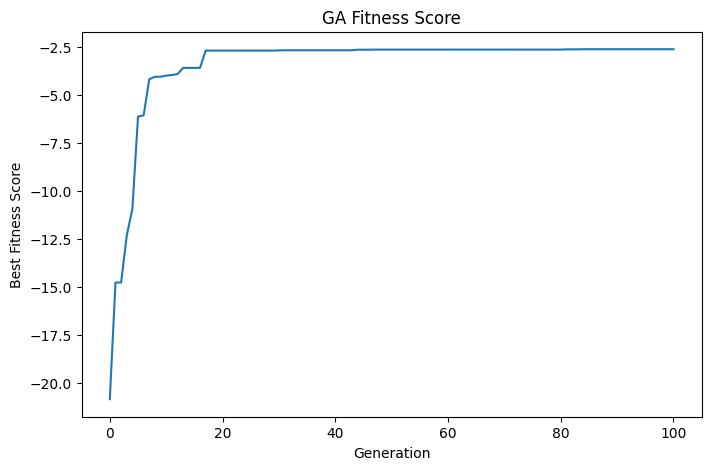

In [42]:
#fitness score
plt.figure(figsize=(8,5))
plt.plot(ga_instance.best_solutions_fitness)
plt.title("GA Fitness Score")
plt.xlabel("Generation")
plt.ylabel("Best Fitness Score")
plt.show()
#The convergence plot shows how the fitness score improved over generations. 
#Since the fitness function is the negative prediction error, 
#a higher fitness score means a lower error. 
#This indicates that the Genetic Algorithm was able to improve the response time formula gradually.

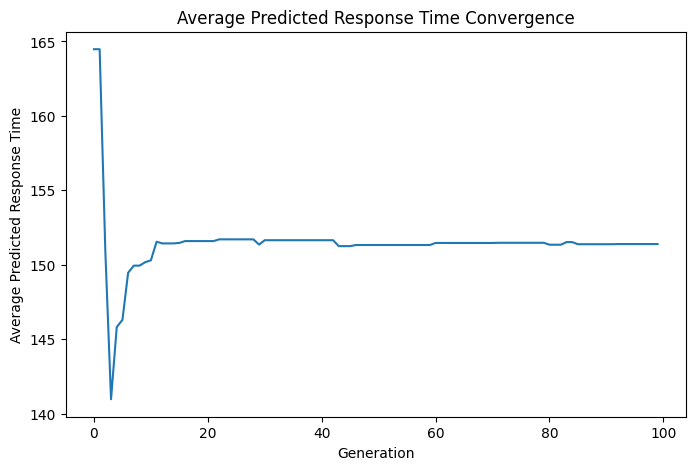

In [45]:
# Plot average predicted response time convergence
plt.figure(figsize=(8, 5))
plt.plot(average_response_time_history)
plt.xlabel("Generation")
plt.ylabel("Average Predicted Response Time")
plt.title("Average Predicted Response Time Convergence")
plt.show()

The average predicted response time changed during the first generations because the Genetic Algorithm was still searching for better weight values. After several generations, the line became stable around a close value. This means the algorithm converged and reached a stable optimized solution.

In [53]:
# Show actual, predicted, and difference for each incident
result_table = ga_data[
    [
        'actual_response_time',
        'Predicted_Response_Time',
        'Difference'
    ]
]
result_table.head(10)
#This table shows the actual response time, the predicted response time, and the difference between them for each incident. 
#The difference helps evaluate how close the optimized GA formula is to the actual response time.

,actual_response_time,Predicted_Response_Time,Difference
210384,167.831051,170.918701,-3.087650
210385,218.895875,215.891634,3.004241
210386,137.430000,142.586942,-5.156942
210387,188.981774,186.569608,2.412166
210388,205.837545,202.130839,3.706706
210389,90.884206,95.957755,-5.073550
210390,155.476167,155.411351,0.064815
210391,119.935936,120.300560,-0.364624
210392,146.020252,143.607895,2.412357
210393,182.590058,181.863271,0.726788


This table shows the actual response time, the predicted response time, and the difference between them for each incident. 
The difference helps evaluate how close the optimized GA formula is to the actual response time.

In [52]:
# Print best values found by GA
print("Best Values Found by GA:")
print("w1 - Distance_to_Incident weight:", w1)
print("w2 - Number_of_Injuries weight:", w2)
print("w3 - Hospital_Capacity weight:", w3)
print("w4 - Fuel_Level weight:", w4)
print("b - Baseline intercept:", b)

Best Values Found by GA:
w1 - Distance_to_Incident weight: 0.7941
w2 - Number_of_Injuries weight: 0.4846
w3 - Hospital_Capacity weight: 0.9647
w4 - Fuel_Level weight: 1.0263
b - Baseline intercept: 6.1118


In [51]:
# Print GA performance results
print("Average Predicted Response Time:", average_predicted_response)
print("Average Actual Response Time:", average_actual_response)
print("Difference between Actual and Predicted Response Time:", average_difference)
print("Mean Absolute Error (MAE):", mae)

Average Predicted Response Time: 151.39571029621172
Average Actual Response Time: 151.40887188671473
Difference between Actual and Predicted Response Time: 0.013161590503046827
Mean Absolute Error (MAE): 2.638802033874439


### Final Interpretation of GA Results: 
The Genetic Algorithm was used to find the best values for the decision variables w1, w2, w3, w4, and b. These values were used to build the final optimized response time formula.

The average predicted response time was very close to the average actual response time. This shows that the optimized formula can estimate the response time with a small difference.

The fitness score convergence plot showed that the GA improved quickly in the first generations, then became stable. This means the algorithm reached a good solution and stopped making large improvements.

The optimized solution can help the emergency response centre make better decisions. For example, distance, number of injuries, hospital capacity, and fuel level can be considered together instead of making decisions based on only one factor. This supports faster and more data-driven emergency response planning.
